# Bank Marketing — KNN riêng

Tách từ `Bank_Marketing_Main.ipynb`: phần **5, 9.2 và 10.2 KNN** cùng bước chuẩn bị dữ liệu.
Đặt notebook cạnh thư mục `data/`, rồi chạy từ trên xuống. Không cần chạy mô hình của thành viên khác.

Nếu thiếu thư viện, chạy trong một cell: `%pip install pandas numpy matplotlib scikit-learn imbalanced-learn`.

**Thực nghiệm:** mặc định dùng 3-fold để giảm thời gian. Mục 10.2 thử 6 tổ hợp (18 lượt CV).
Giữ cách chia train/test của file Main: 80/20, stratify, random_state=42; bỏ `duration`.
Chọn ngưỡng và siêu tham số bằng train/CV. Bảng test dùng để báo cáo, không dùng để quyết định lần thử tiếp theo.
Kết quả CV và kết quả test được lưu riêng; không so trực tiếp điểm OOF chọn ngưỡng với trung bình CV như cùng một phép đo.

## Chuẩn bị dữ liệu
Chỉ sao chép bước dùng chung cần thiết; giữ nguyên cách xử lý của file Main.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Giữ 3 khi thử nhanh; đổi thành 5 khi kiểm tra cấu hình đã thu hẹp.
N_FOLDS = 3

In [2]:
import pandas as pd

df = pd.read_csv("data/bank-additional-full.csv", sep=";")
df.head()

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Giữ "unknown" như một nhóm riêng; loại bản ghi trùng và thiếu nhãn.
df_model = df.drop_duplicates().dropna(subset=["y"]).copy()

# duration chỉ biết sau cuộc gọi, không dùng để dự đoán trước cuộc gọi.
X = df_model.drop(columns=["y", "duration"])
y = df_model["y"].map({"no": 0, "yes": 1})

numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)
categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features),
    ]
)

# Chỉ fit trên train để tránh rò rỉ thông tin từ tập test.
X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)
feature_names = preprocessor.get_feature_names_out()

print(f"Số dòng sau khi loại trùng/thiếu nhãn: {len(df_model)}")
print(f"Số đặc trưng sau mã hóa: {len(feature_names)}")
print(f"Train: X={X_train.shape}, y={y_train.shape}")
print(f"Test:  X={X_test.shape}, y={y_test.shape}")
print("Tỷ lệ nhãn trong train (%):")
print(y_train.map({0: "no", 1: "yes"}).value_counts(normalize=True).mul(100).round(2))

Số dòng sau khi loại trùng/thiếu nhãn: 41176
Số đặc trưng sau mã hóa: 62
Train: X=(32940, 62), y=(32940,)
Test:  X=(8236, 62), y=(8236,)
Tỷ lệ nhãn trong train (%):
y
no     88.73
yes    11.27
Name: proportion, dtype: float64


### 5. Thuật toán K-Nearest Neighbors (KNN)

#### 5.1. Giới thiệu thuật toán

K-Nearest Neighbors (KNN) là thuật toán học máy có giám sát, được sử dụng trong các bài toán phân loại và hồi quy.

Đối với bài toán Bank Marketing, KNN dự đoán khách hàng có đăng ký tiền gửi kỳ hạn hay không dựa trên nhãn chiếm đa số của K khách hàng gần nhất trong không gian đặc trưng.

- **Ưu điểm:** dễ hiểu, không giả định dạng phân phối của dữ liệu.
- **Nhược điểm:** dự đoán chậm khi dữ liệu lớn, nhạy với thang đo của các đặc trưng (nên cần dữ liệu đã chuẩn hóa ở mục 3) và nhạy với dữ liệu mất cân bằng: lớp "no" chiếm đa số nên các láng giềng gần nhất thường là "no".

Cấu hình baseline: K = 5 và khoảng cách Euclidean. KNN không hỗ trợ `class_weight` nên bản baseline chưa có cơ chế xử lý mất cân bằng lớp.

#### 5.2. Huấn luyện và dự đoán

Với KNN, bước huấn luyện chỉ là lưu lại tập train; việc tìm láng giềng diễn ra khi dự đoán. Sau đó dự đoán nhãn (0: không đăng ký, 1: đăng ký) và xác suất đăng ký trên tập test.

In [4]:
from sklearn.neighbors import KNeighborsClassifier

# Khởi tạo mô hình KNN baseline
model_knn = KNeighborsClassifier(
    n_neighbors=5,
    metric="euclidean"
)

# Huấn luyện trên tập train
model_knn.fit(X_train, y_train)

# Dự đoán nhãn và xác suất đăng ký (lớp "yes") trên tập test
y_pred_knn = model_knn.predict(X_test)
y_proba_knn = model_knn.predict_proba(X_test)[:, 1]

print("Huấn luyện và dự đoán KNN hoàn tất!")
print("\n10 nhãn dự đoán đầu tiên:", y_pred_knn[:10])

Huấn luyện và dự đoán KNN hoàn tất!

10 nhãn dự đoán đầu tiên: [0 1 0 0 0 0 0 0 0 0]


#### 5.3. Đánh giá mô hình

Đánh giá trên tập test bằng F1-score, Recall, ROC-AUC (độ đo thầy gợi ý), bổ sung Accuracy và Precision. Do dữ liệu mất cân bằng nên F1-score và Recall được ưu tiên hơn Accuracy.

In [5]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Tính các chỉ số
accuracy_knn = accuracy_score(y_test, y_pred_knn)
precision_knn = precision_score(y_test, y_pred_knn, zero_division=0)
recall_knn = recall_score(y_test, y_pred_knn, zero_division=0)
f1_knn = f1_score(y_test, y_pred_knn, zero_division=0)
auc_knn = roc_auc_score(y_test, y_proba_knn)

# Hiển thị kết quả
print("===== KNN BASELINE =====")
print(f"Accuracy : {accuracy_knn:.4f}")
print(f"Precision: {precision_knn:.4f}")
print(f"Recall   : {recall_knn:.4f}")
print(f"F1-score : {f1_knn:.4f}")
print(f"ROC-AUC  : {auc_knn:.4f}")

# Báo cáo chi tiết theo từng lớp
print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(
    y_test,
    y_pred_knn,
    target_names=["No", "Yes"],
    zero_division=0
))

===== KNN BASELINE =====
Accuracy : 0.8955
Precision: 0.5661
Recall   : 0.3093
F1-score : 0.4000
ROC-AUC  : 0.7405

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

          No       0.92      0.97      0.94      7308
         Yes       0.57      0.31      0.40       928

    accuracy                           0.90      8236
   macro avg       0.74      0.64      0.67      8236
weighted avg       0.88      0.90      0.88      8236



#### 5.4. Trực quan hóa kết quả

Confusion Matrix cho biết số khách hàng mô hình đoán đúng và sai ở từng lớp, đặc biệt là số khách hàng thật sự đăng ký nhưng bị bỏ sót (False Negative). ROC Curve cho biết khả năng phân biệt hai lớp ở mọi ngưỡng phân loại.

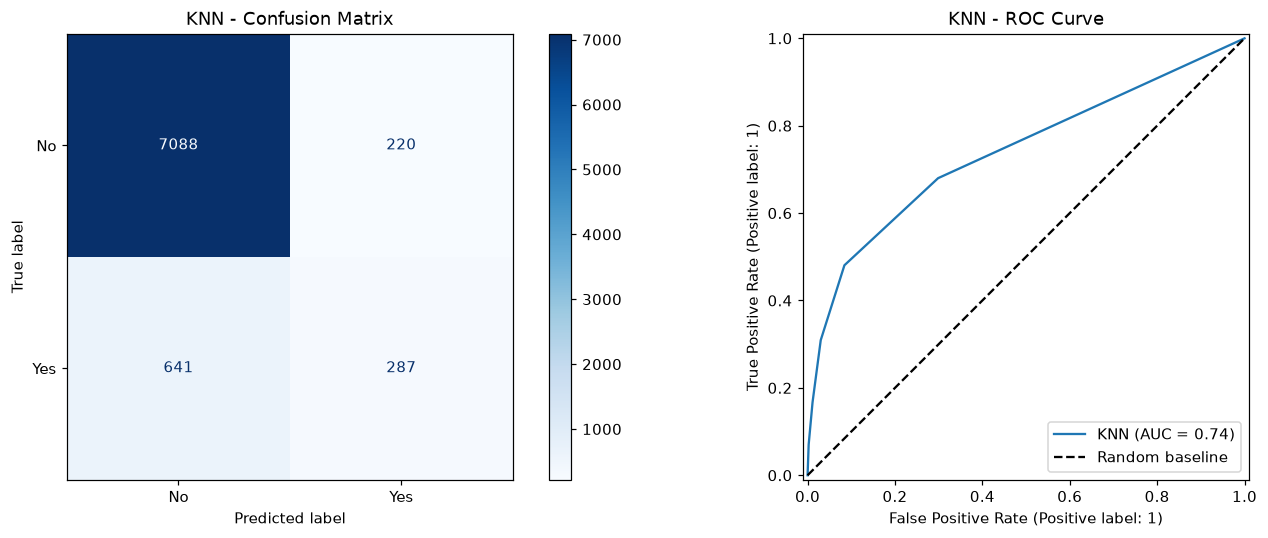

In [6]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_knn,
    display_labels=["No", "Yes"],
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("KNN - Confusion Matrix")

# Biểu đồ ROC Curve
RocCurveDisplay.from_predictions(
    y_test,
    y_proba_knn,
    name="KNN",
    ax=axes[1]
)
axes[1].plot([0, 1], [0, 1], "k--", label="Random baseline")
axes[1].set_title("KNN - ROC Curve")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

#### 5.5. Nhận xét
Ghi theo kết quả vừa chạy: F1 = …, Recall = …, ROC-AUC = … .
KNN có bỏ sót nhiều khách đăng ký không? Vì sao cần thử SMOTE hoặc chỉnh ngưỡng?

In [7]:
# Danh sách kết quả chung của cả nhóm (tạo mới nếu chưa có)
if "all_results" not in globals():
    all_results = []
if "all_probas" not in globals():
    all_probas = {}

all_results.append({
    "Model": "KNN (baseline)",
    "Accuracy": accuracy_knn,
    "Precision": precision_knn,
    "Recall": recall_knn,
    "F1-score": f1_knn,
    "ROC-AUC": auc_knn
})
all_probas["KNN (baseline)"] = y_proba_knn

print("Đã lưu kết quả KNN!")

Đã lưu kết quả KNN!


## 9.2. KNN — Xử lý mất cân bằng và chỉnh ngưỡng

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.base import clone
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict,
    GridSearchCV,
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    precision_recall_curve,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
)
from imblearn.over_sampling import SMOTE


def knn_metrics(y_true, y_pred, y_proba):
    """Đánh giá với lớp yes = 1 là lớp dương."""
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
    }


def knn_save_result(name, metrics, proba):
    """Lưu vào kết quả chung; thay kết quả cũ nếu chạy lại cell."""
    global all_results, all_probas

    if "all_results" not in globals():
        all_results = []
    if "all_probas" not in globals():
        all_probas = {}

    all_results[:] = [
        row for row in all_results if row["Model"] != name
    ]
    all_results.append({"Model": name, **metrics})
    all_probas[name] = proba


def knn_report(name, y_pred, y_proba):
    """In độ đo, vẽ biểu đồ và lưu kết quả."""
    metrics = knn_metrics(y_test, y_pred, y_proba)

    print(f"===== {name.upper()} =====")
    for metric, value in metrics.items():
        print(f"{metric:<10}: {value:.4f}")

    print("\n===== CLASSIFICATION REPORT =====")
    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["No", "Yes"],
        zero_division=0,
    ))

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=[0, 1],
        display_labels=["No", "Yes"],
        cmap="Blues",
        ax=axes[0],
    )
    axes[0].set_title(f"{name} - Confusion Matrix")

    RocCurveDisplay.from_predictions(
        y_test,
        y_proba,
        name=name,
        ax=axes[1],
    )
    axes[1].plot([0, 1], [0, 1], "k--", label="Random baseline")
    axes[1].set_title(f"{name} - ROC Curve")
    axes[1].legend(loc="lower right")

    plt.tight_layout()
    plt.show()

    knn_save_result(name, metrics, y_proba)
    return metrics

#### 9.2.1 Cân bằng dữ liệu bằng SMOTE

SMOTE chỉ áp dụng trên train. Hạn chế: nội suy sau One-Hot có thể tạo giá trị thập phân ở các cột phân loại.

In [9]:
from imblearn.over_sampling import SMOTE
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, roc_auc_score

print("Đang chạy KNN + SMOTE...", flush=True)

X_knn_smote, y_knn_smote = SMOTE(
    random_state=42
).fit_resample(X_train, y_train)

model_knn_smote = KNeighborsClassifier(
    n_neighbors=5,
    metric="euclidean"
)
model_knn_smote.fit(X_knn_smote, y_knn_smote)

y_pred_knn_smote = model_knn_smote.predict(X_test)
y_proba_knn_smote = model_knn_smote.predict_proba(X_test)[:, 1]

print(classification_report(
    y_test, y_pred_knn_smote,
    target_names=["No", "Yes"],
    zero_division=0
))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba_knn_smote), 4))
metrics_knn_smote = knn_metrics(y_test, y_pred_knn_smote, y_proba_knn_smote)
knn_save_result("KNN (SMOTE)", metrics_knn_smote, y_proba_knn_smote)

Đang chạy KNN + SMOTE...
              precision    recall  f1-score   support

          No       0.94      0.75      0.84      7308
         Yes       0.24      0.63      0.35       928

    accuracy                           0.74      8236
   macro avg       0.59      0.69      0.59      8236
weighted avg       0.86      0.74      0.78      8236

ROC-AUC: 0.7314


#### 9.2.2. Chỉnh ngưỡng phân loại

Chọn ngưỡng từ dự đoán chéo trên train; tiền xử lý fit riêng trong mỗi fold. Không chọn ngưỡng trên test.

Đang chọn ngưỡng bằng 3-fold...
Ngưỡng được chọn trên train: 0.4000
F1 OOF tại ngưỡng này: 0.4199
===== KNN (THRESHOLD) =====
Accuracy  : 0.8667
Precision : 0.4200
Recall    : 0.4806
F1-score  : 0.4482
ROC-AUC   : 0.7405

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

          No       0.93      0.92      0.92      7308
         Yes       0.42      0.48      0.45       928

    accuracy                           0.87      8236
   macro avg       0.68      0.70      0.69      8236
weighted avg       0.88      0.87      0.87      8236



,Threshold,Precision,Recall,F1-score
0,0.0,0.1127,1.0000,0.2025
1,0.2,0.2169,0.6543,0.3258
2,0.4,0.3974,0.4452,0.4199
3,0.6,0.5337,0.2905,0.3762
4,0.8,0.6389,0.1506,0.2438
5,1.0,0.7171,0.0485,0.0909


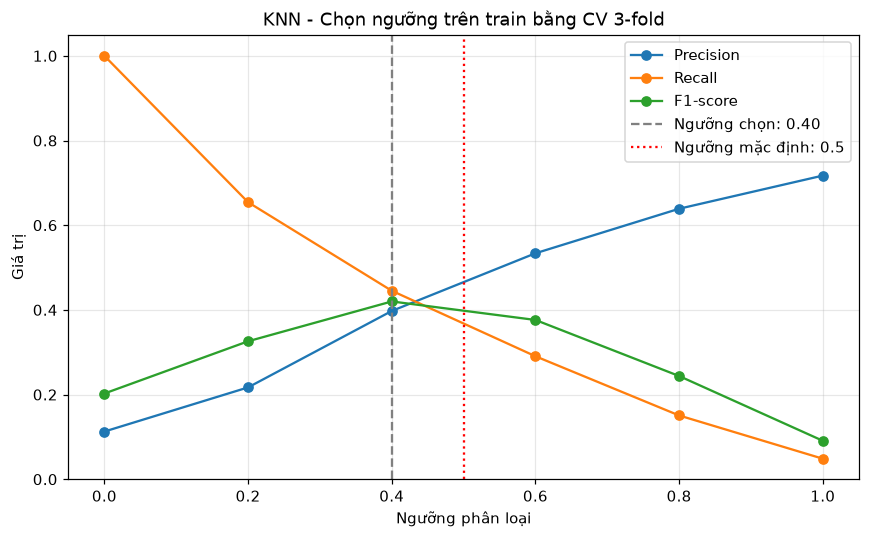

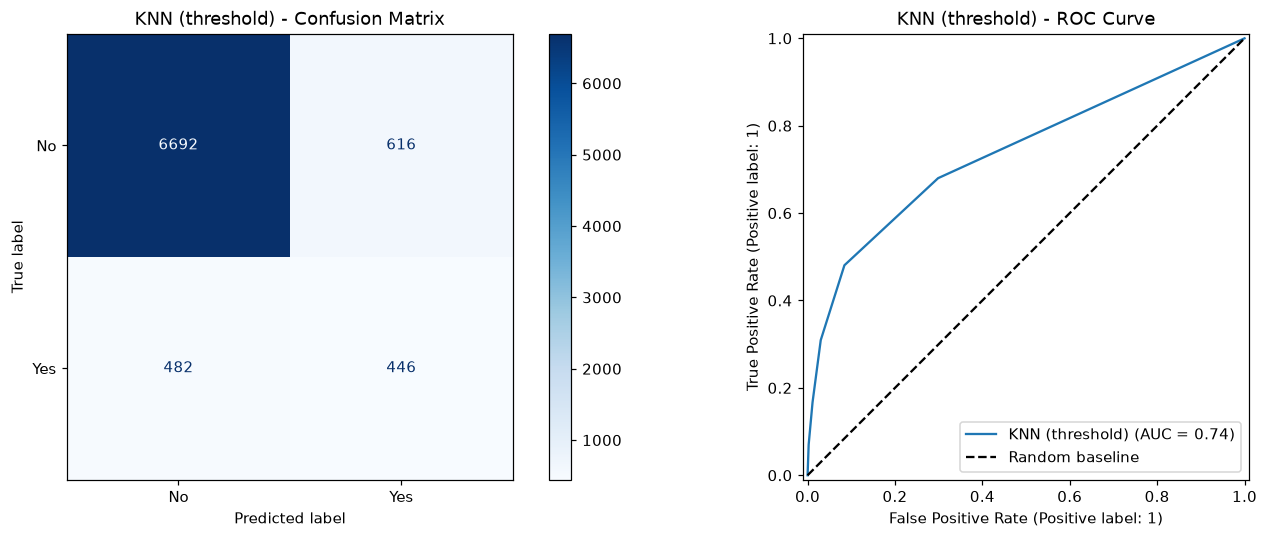

In [10]:
print(f"Đang chọn ngưỡng bằng {N_FOLDS}-fold...", flush=True)

cv_knn_threshold = StratifiedKFold(
    n_splits=N_FOLDS,
    shuffle=True,
    random_state=42,
)

knn_threshold_pipeline = SkPipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        ("knn", clone(model_knn).set_params(n_jobs=1)),
    ]
)

# Mỗi mẫu train được dự đoán bởi mô hình chưa học mẫu đó.
oof_proba_knn = cross_val_predict(
    knn_threshold_pipeline,
    X_train_raw,
    y_train,
    cv=cv_knn_threshold,
    method="predict_proba",
    n_jobs=2,
)[:, 1]

# Xét các ngưỡng tương ứng với xác suất OOF thực tế.
precision_oof, recall_oof, thresholds_knn = precision_recall_curve(
    y_train,
    oof_proba_knn,
)

# Phần tử cuối của precision/recall không có ngưỡng tương ứng.
f1_oof = np.divide(
    2 * precision_oof[:-1] * recall_oof[:-1],
    precision_oof[:-1] + recall_oof[:-1],
    out=np.zeros_like(precision_oof[:-1]),
    where=(precision_oof[:-1] + recall_oof[:-1]) > 0,
)

df_thr_knn = pd.DataFrame({
    "Threshold": thresholds_knn,
    "Precision": precision_oof[:-1],
    "Recall": recall_oof[:-1],
    "F1-score": f1_oof,
})

best_idx_knn = df_thr_knn["F1-score"].idxmax()
best_threshold_knn = float(
    df_thr_knn.loc[best_idx_knn, "Threshold"]
)

display(df_thr_knn.round(4))
print(f"Ngưỡng được chọn trên train: {best_threshold_knn:.4f}")
print(f"F1 OOF tại ngưỡng này: {f1_oof[best_idx_knn]:.4f}")

plt.figure(figsize=(8, 5))

for metric in ["Precision", "Recall", "F1-score"]:
    plt.plot(
        df_thr_knn["Threshold"],
        df_thr_knn[metric],
        marker="o",
        label=metric,
    )

plt.axvline(
    best_threshold_knn,
    color="gray",
    linestyle="--",
    label=f"Ngưỡng chọn: {best_threshold_knn:.2f}",
)
plt.axvline(
    0.5,
    color="red",
    linestyle=":",
    label="Ngưỡng mặc định: 0.5",
)

plt.title(f"KNN - Chọn ngưỡng trên train bằng CV {N_FOLDS}-fold")
plt.xlabel("Ngưỡng phân loại")
plt.ylabel("Giá trị")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Dùng xác suất baseline đã có từ mục 5.
y_pred_knn_thr = (
    y_proba_knn >= best_threshold_knn
).astype(int)

metrics_knn_thr = knn_report(
    "KNN (threshold)",
    y_pred_knn_thr,
    y_proba_knn,
)

#### 9.2.3. So sánh với baseline


KNN (SMOTE) so với baseline:
  Chênh lệch Precision: -0.3212
  Chênh lệch Recall: +0.3222
  Chênh lệch F1-score: -0.0471
  Chênh lệch ROC-AUC: -0.0091

KNN (threshold) so với baseline:
  Chênh lệch Precision: -0.1461
  Chênh lệch Recall: +0.1713
  Chênh lệch F1-score: +0.0482
  Chênh lệch ROC-AUC: +0.0000


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
KNN (baseline),0.8955,0.5661,0.3093,0.4000,0.7405
KNN (SMOTE),0.7391,0.2449,0.6315,0.3529,0.7314
KNN (threshold),0.8667,0.4200,0.4806,0.4482,0.7405


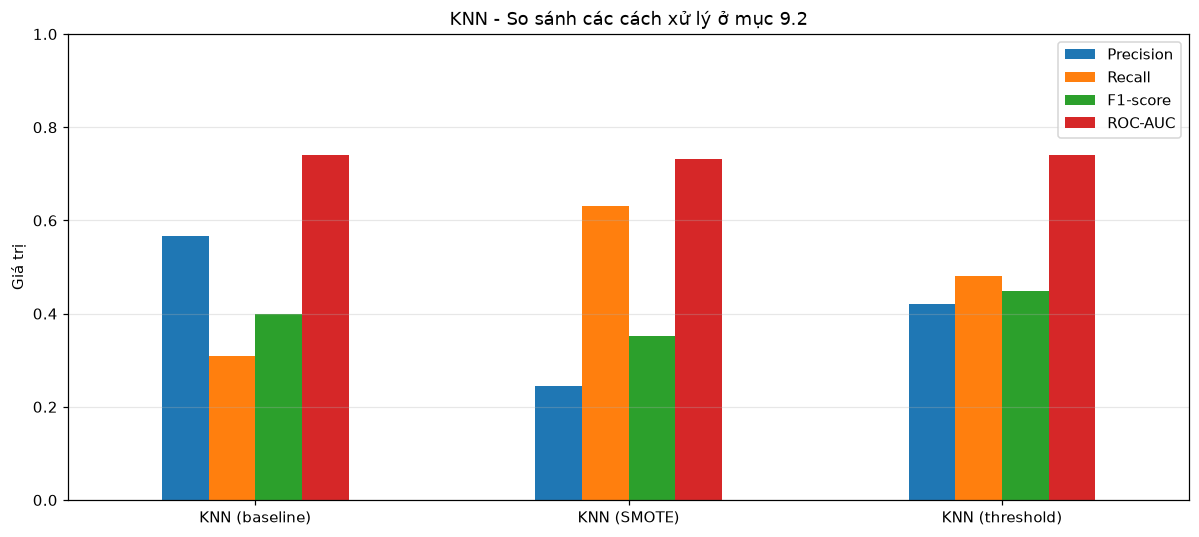

In [11]:
metrics_knn_smote = knn_metrics(
    y_test, y_pred_knn_smote, y_proba_knn_smote
)

metrics_knn_thr = knn_metrics(
    y_test, y_pred_knn_thr, y_proba_knn
)
metrics_knn_baseline = knn_metrics(
    y_test,
    y_pred_knn,
    y_proba_knn,
)

df_knn_section9 = pd.DataFrame([
    {"Model": "KNN (baseline)", **metrics_knn_baseline},
    {"Model": "KNN (SMOTE)", **metrics_knn_smote},
    {"Model": "KNN (threshold)", **metrics_knn_thr},
]).set_index("Model")

display(df_knn_section9.round(4))

df_knn_section9[["Precision", "Recall", "F1-score", "ROC-AUC"]].plot(
    kind="bar",
    figsize=(11, 5),
    ylim=(0, 1),
    rot=0,
)

plt.title("KNN - So sánh các cách xử lý ở mục 9.2")
plt.xlabel("")
plt.ylabel("Giá trị")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

for name in ["KNN (SMOTE)", "KNN (threshold)"]:
    delta = (
        df_knn_section9.loc[name]
        - df_knn_section9.loc["KNN (baseline)"]
    )
    print(f"\n{name} so với baseline:")
    for metric in ["Precision", "Recall", "F1-score", "ROC-AUC"]:
        print(f"  Chênh lệch {metric}: {delta[metric]:+.4f}")

## 10.2. KNN — Tinh chỉnh siêu tham số
Tìm trên train gốc, giữ ngưỡng mặc định. Tối ưu F1; ghi thêm Recall và ROC-AUC.

#### 10.2.1. Tìm kiếm siêu tham số

In [12]:
import time

pipeline_knn_tuning = SkPipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        ("knn", KNeighborsClassifier(
            metric="minkowski",
            n_jobs=1,
        )),
    ]
)

# p=1: Manhattan; p=2: Euclidean.
param_grid_knn = {
    "knn__n_neighbors": [5, 11, 21],
    "knn__weights": ["uniform", "distance"],
    "knn__p": [2],
}

cv_knn_tuning = StratifiedKFold(
    n_splits=N_FOLDS,
    shuffle=True,
    random_state=42,
)

search_knn = GridSearchCV(
    estimator=pipeline_knn_tuning,
    param_grid=param_grid_knn,
    scoring={
        "f1": "f1",
        "recall": "recall",
        "roc_auc": "roc_auc",
    },
    refit="f1",
    cv=cv_knn_tuning,
    n_jobs=2,
    pre_dispatch=2,
    verbose=2,
    error_score="raise",
)

start_knn = time.perf_counter()

# Pipeline fit tiền xử lý riêng trong từng fold.
search_knn.fit(X_train_raw, y_train)

elapsed_knn = time.perf_counter() - start_knn

print(f"\nThời gian tìm kiếm: {elapsed_knn / 60:.2f} phút")
print("Tham số tốt nhất:", search_knn.best_params_)
print(f"F1-score CV tốt nhất: {search_knn.best_score_:.4f}")

cv_results_knn = pd.DataFrame(search_knn.cv_results_)

cols_knn = [
    "rank_test_f1",
    "mean_test_f1",
    "std_test_f1",
    "mean_test_recall",
    "mean_test_roc_auc",
    "params",
]

display(
    cv_results_knn
    .sort_values("rank_test_f1")[cols_knn]
    .head(10)
    .reset_index(drop=True)
    .round(4)
)

Fitting 3 folds for each of 6 candidates, totalling 18 fits

Thời gian tìm kiếm: 0.84 phút
Tham số tốt nhất: {'knn__n_neighbors': 5, 'knn__p': 2, 'knn__weights': 'uniform'}
F1-score CV tốt nhất: 0.3762


,rank_test_f1,mean_test_f1,std_test_f1,mean_test_recall,mean_test_roc_auc,params
0,1,0.3762,0.0096,0.2905,0.7221,"{'knn__n_neighbors': 5, 'knn__p': 2, 'knn__wei..."
1,2,0.3696,0.0129,0.2988,0.7194,"{'knn__n_neighbors': 5, 'knn__p': 2, 'knn__wei..."
2,3,0.3647,0.0138,0.2746,0.7424,"{'knn__n_neighbors': 11, 'knn__p': 2, 'knn__we..."
3,4,0.3594,0.0112,0.2606,0.7467,"{'knn__n_neighbors': 11, 'knn__p': 2, 'knn__we..."
4,5,0.3564,0.0098,0.2592,0.7557,"{'knn__n_neighbors': 21, 'knn__p': 2, 'knn__we..."
5,6,0.3526,0.0130,0.2468,0.7618,"{'knn__n_neighbors': 21, 'knn__p': 2, 'knn__we..."


#### Nhật ký các lần tìm kiếm trên train
Cell dưới lưu từng cấu hình CV vào CSV và giữ lịch sử các lần chạy. Muốn thử tiếp: thay một lựa chọn trong `param_grid_knn`, chạy lại tìm kiếm rồi chạy cell lưu nhật ký. So sánh các cấu hình với cùng dữ liệu và số fold. Điểm CV dùng chọn cấu hình; test chỉ dùng báo cáo cuối. Việc chạy lại y hệt cấu hình có thể cho cùng kết quả.

In [13]:
from pathlib import Path
from datetime import datetime

output_dir = Path("ket_qua_knn")
output_dir.mkdir(exist_ok=True)

# Sửa ghi chú cho từng lần thử trước khi lưu.
GHI_CHU = "Khảo sát K=5,11,21; uniform/distance; Euclidean"
run_id = datetime.now().isoformat(timespec="microseconds")
nhat_ky = cv_results_knn[cols_knn].copy()
nhat_ky.insert(0, "Thoi_diem", run_id)
nhat_ky.insert(1, "So_fold", N_FOLDS)
nhat_ky["Ghi_chu"] = GHI_CHU
history_file = output_dir / "nhat_ky_cv.csv"
nhat_ky.to_csv(history_file, mode="a", header=not history_file.exists(), index=False)
display(nhat_ky.round(4))
print("Đã lưu nhật ký:", history_file)

Đã lưu nhật ký: ket_qua_knn\nhat_ky_cv.csv


,Thoi_diem,So_fold,rank_test_f1,mean_test_f1,std_test_f1,mean_test_recall,mean_test_roc_auc,params,Ghi_chu
0,2026-11-21T16:40:50.580057,3,1,0.3762,0.0096,0.2905,0.7221,"{'knn__n_neighbors': 5, 'knn__p': 2, 'knn__wei...","Khảo sát K=5,11,21; uniform/distance; Euclidean"
1,2026-11-21T16:40:50.580057,3,2,0.3696,0.0129,0.2988,0.7194,"{'knn__n_neighbors': 5, 'knn__p': 2, 'knn__wei...","Khảo sát K=5,11,21; uniform/distance; Euclidean"
2,2026-11-21T16:40:50.580057,3,4,0.3594,0.0112,0.2606,0.7467,"{'knn__n_neighbors': 11, 'knn__p': 2, 'knn__we...","Khảo sát K=5,11,21; uniform/distance; Euclidean"
3,2026-11-21T16:40:50.580057,3,3,0.3647,0.0138,0.2746,0.7424,"{'knn__n_neighbors': 11, 'knn__p': 2, 'knn__we...","Khảo sát K=5,11,21; uniform/distance; Euclidean"
4,2026-11-21T16:40:50.580057,3,6,0.3526,0.0130,0.2468,0.7618,"{'knn__n_neighbors': 21, 'knn__p': 2, 'knn__we...","Khảo sát K=5,11,21; uniform/distance; Euclidean"
5,2026-11-21T16:40:50.580057,3,5,0.3564,0.0098,0.2592,0.7557,"{'knn__n_neighbors': 21, 'knn__p': 2, 'knn__we...","Khảo sát K=5,11,21; uniform/distance; Euclidean"


#### 10.2.2. Đánh giá mô hình sau tinh chỉnh

===== KNN (TUNED) =====
Accuracy  : 0.8955
Precision : 0.5661
Recall    : 0.3093
F1-score  : 0.4000
ROC-AUC   : 0.7405

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

          No       0.92      0.97      0.94      7308
         Yes       0.57      0.31      0.40       928

    accuracy                           0.90      8236
   macro avg       0.74      0.64      0.67      8236
weighted avg       0.88      0.90      0.88      8236


Tham số KNN tốt nhất:
{'knn__n_neighbors': 5, 'knn__p': 2, 'knn__weights': 'uniform'}

Chênh lệch sau tinh chỉnh so với baseline:
Accuracy  : +0.0000
Precision : +0.0000
Recall    : +0.0000
F1-score  : +0.0000
ROC-AUC   : +0.0000


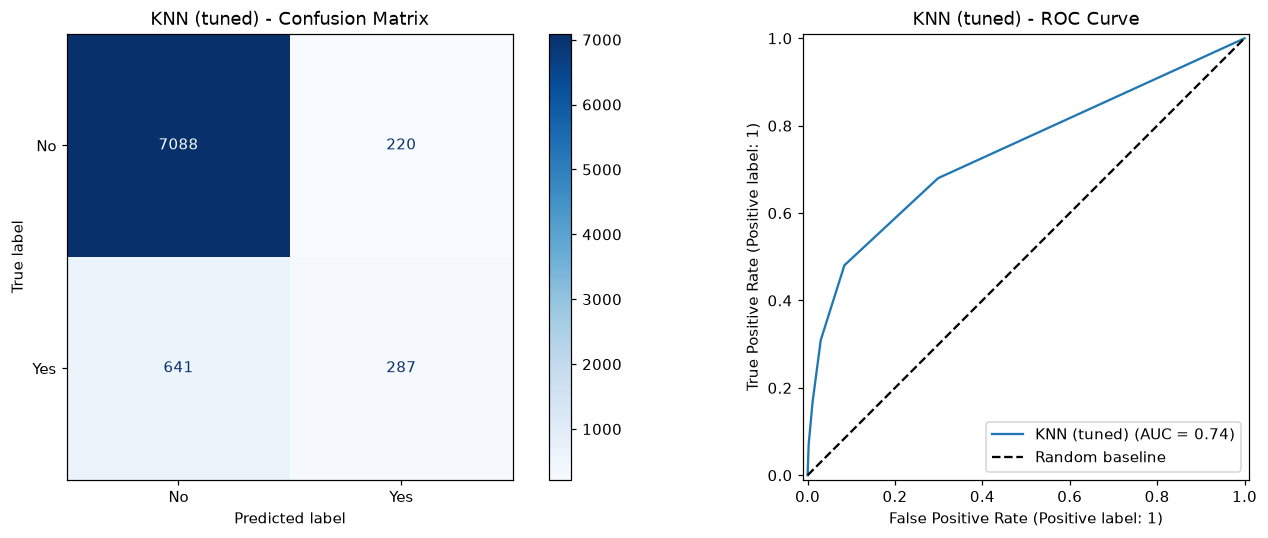

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
KNN (baseline),0.8955,0.5661,0.3093,0.4000,0.7405
KNN (SMOTE),0.7391,0.2449,0.6315,0.3529,0.7314
KNN (threshold),0.8667,0.4200,0.4806,0.4482,0.7405
KNN (tuned),0.8955,0.5661,0.3093,0.4000,0.7405


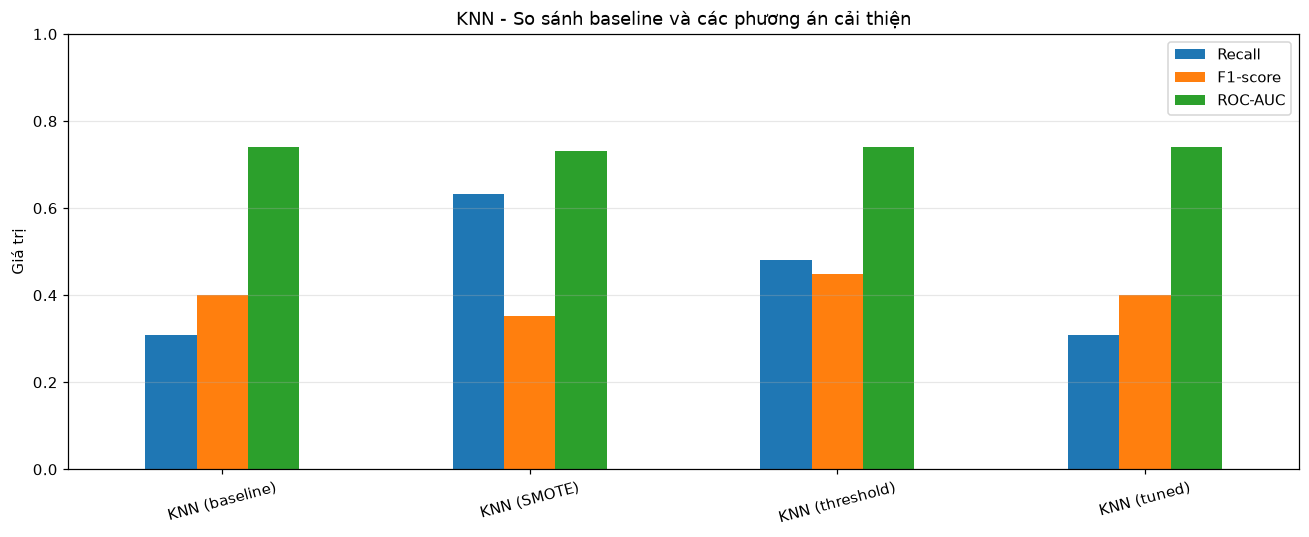

In [14]:
# GridSearchCV đã refit mô hình tốt nhất trên toàn bộ train.
model_knn_tuned = search_knn.best_estimator_

y_pred_knn_tuned = model_knn_tuned.predict(X_test_raw)
y_proba_knn_tuned = model_knn_tuned.predict_proba(X_test_raw)[:, 1]

metrics_knn_tuned = knn_report(
    "KNN (tuned)",
    y_pred_knn_tuned,
    y_proba_knn_tuned,
)

# So sánh cả bốn phiên bản KNN.
df_knn_compare = pd.DataFrame([
    {"Model": "KNN (baseline)", **metrics_knn_baseline},
    {"Model": "KNN (SMOTE)", **metrics_knn_smote},
    {"Model": "KNN (threshold)", **metrics_knn_thr},
    {"Model": "KNN (tuned)", **metrics_knn_tuned},
]).set_index("Model")

display(df_knn_compare.round(4))

df_knn_compare[["Recall", "F1-score", "ROC-AUC"]].plot(
    kind="bar",
    figsize=(12, 5),
    ylim=(0, 1),
    rot=15,
)

plt.title("KNN - So sánh baseline và các phương án cải thiện")
plt.xlabel("")
plt.ylabel("Giá trị")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("\nTham số KNN tốt nhất:")
print(search_knn.best_params_)

print("\nChênh lệch sau tinh chỉnh so với baseline:")
for metric in metrics_knn_baseline:
    difference = (
        metrics_knn_tuned[metric] - metrics_knn_baseline[metric]
    )
    print(f"{metric:<10}: {difference:+.4f}")

In [15]:
# Bảng test phục vụ báo cáo; tách riêng với nhật ký lựa chọn cấu hình trên train.
df_knn_compare.to_csv(output_dir / "so_sanh_test.csv", encoding="utf-8-sig")
df_thr_knn.to_csv(output_dir / "chon_nguong_oof.csv", index=False, encoding="utf-8-sig")
print("Đã lưu bảng test và bảng chọn ngưỡng vào", output_dir)

Đã lưu bảng test và bảng chọn ngưỡng vào ket_qua_knn


## Ghi nhận sau thực nghiệm

| Lần thử | Thay đổi và lý do | Kết quả CV | Quyết định tiếp theo |
|---|---|---|---|
| 1 | Baseline K=5 | Điền sau khi chạy | … |
| 2 | Thử các K, weights ở mục 10.2 | Xem nhat_ky_cv.csv | … |
| 3 | Thử thêm lựa chọn theo kết quả train | Điền sau khi chạy | … |

Ghi cả lần thử không cải thiện. Các dòng này là mẫu ghi chép, không phải thực nghiệm đã hoàn thành.
Baseline test ở mục 5 không phải điểm CV; muốn có CV cho baseline, xem dòng K=5, uniform, p=2 ở mục 10.2.
SMOTE và chỉnh ngưỡng là hai thử nghiệm riêng; notebook này không tự kết hợp chúng với mô hình tuned.